# PARCIAL 02 - INF 672
 **Estudiante:** Anahi Lourdes Oquendo Chucusea                                                                                                         
 **Semestre:** 6º semestre                                                                                                                              
 **Gestión:** 2026-02                                                                                                                                   
 **Docente:** M. Sc. Huáscar Fedor Gonzales Guzmán                                                                                                                                                                                        **Fecha de presentacion:** 11/11/2026

# EJERCICIO 01   
Carga y exploración del dataset de reseñas de IMDB

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar el dataset local
df = pd.read_csv('IMDB Dataset.csv')

# Mostrar las primeras filas
display(df.head())

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [11]:
# Verificar información general, valores nulos y duplicados
resumen_df = pd.DataFrame({
    'Tipo de Dato': df.dtypes,
    'Valores No Nulos': df.notnull().sum(),
    'Valores Nulos (NaN)': df.isnull().sum()
})

display(resumen_df)
print(f"Total de filas duplicadas: {df.duplicated().sum()}")

,Tipo de Dato,Valores No Nulos,Valores Nulos (NaN)
review,str,49582,0
sentiment,str,49582,0
word_count,int64,49582,0


Total de filas duplicadas: 0


In [3]:
# Eliminar duplicados
df = df.drop_duplicates().reset_index(drop=True)
print(f"Total de filas después de eliminar duplicados: {len(df)}")


Total de filas después de eliminar duplicados: 49582


In [4]:
# Distribución de clases
print("\nDistribución de clases (sentiment):")
print(df['sentiment'].value_counts())


Distribución de clases (sentiment):
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


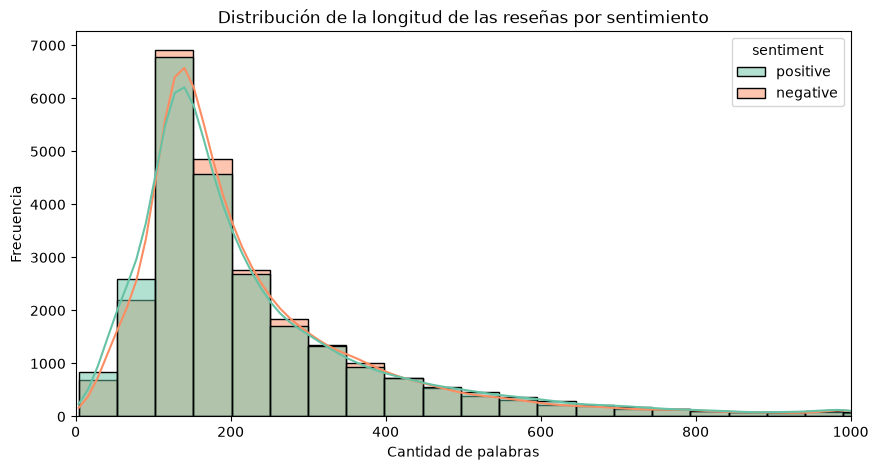

In [8]:
# Calcular la longitud de las reseñas en palabras
df['word_count'] = df['review'].apply(lambda x: len(str(x).split()))

# Gráfico de distribución de longitud por clase
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='word_count', hue='sentiment', bins=50, kde=True, palette='Set2')
plt.title('Distribución de la longitud de las reseñas por sentimiento')
plt.xlabel('Cantidad de palabras')
plt.ylabel('Frecuencia')
plt.xlim(0, 1000)
plt.show()

## Análisis y respuestas:
* **¿Qué muestra la exploración?** El dataset contiene 50 000 reseñas balanceadas equitativamente entre las clases *positive* y *negative*[cite: 19, 20]. Tras limpiar los duplicados, nos aseguramos de que el modelo aprenda con datos únicos.
* **Longitud de las reseñas:** El histograma muestra que la mayoría de las opiniones se concentran entre 100 y 300 palabras para ambas clases, indicando que la extensión por sí sola no determina el sentimiento.

# EJERCICIO 02   
Preprocesamiento del texto y manejo de stopwords

In [14]:
import re
import nltk
from nltk.corpus import stopwords

# Descargar stopwords de forma silenciosa para evitar alertas en pantalla
nltk.download('stopwords', quiet=True)

# Trabajar inicialmente con una muestra de 5 000 reseñas[cite: 20]
df_sample = df.sample(n=5000, random_state=42).reset_index(drop=True)

# Configurar stopwords conservando las palabras de negación importantes
stop_words_original = set(stopwords.words('english'))
palabras_negacion = {
    'not', 'no', 'nor', 'but', 'ain', 'aren', "aren't", 'couldn', "couldn't", 
    'didn', "didn't", 'doesn', "doesn't", 'hadn', "hadn't", 'hasn', "hasn't", 
    'haven', "haven't", 'isn', "isn't", 'mightn', "mightn't", 'mustn', 
    "mustn't", 'needn', "needn't", 'shan', "shan't", 'shouldn', "shouldn't", 
    'wasn', "wasn't", 'weren', "weren't", 'won', "won't", 'wouldn', "wouldn't"
}

stop_words_filtradas = stop_words_original - palabras_negacion

def limpiar_texto(texto):
    # Eliminar etiquetas HTML (<br />)[cite: 20]
    texto = re.sub(r'<.*?>', ' ', texto)
    # Convertir a minúsculas
    texto = texto.lower()
    # Eliminar caracteres especiales y números
    texto = re.sub(r'[^a-zA-Z\s]', '', texto)
    # Filtrar stopwords conservando negaciones
    palabras = texto.split()
    palabras_limpias = [p for p in palabras if p not in stop_words_filtradas]
    return ' '.join(palabras_limpias)

df_sample['clean_review'] = df_sample['review'].apply(limpiar_texto)

print("--- EJEMPLO DE PREPROCESAMIENTO DE TEXTO ---")
print("• Original:\n", df_sample['review'][0][:250], "...\n")
print("• Limpio:\n", df_sample['clean_review'][0][:250], "...")

--- EJEMPLO DE PREPROCESAMIENTO DE TEXTO ---
• Original:
 "Soul Plane" is a horrible attempt at comedy that only should appeal people with thick skulls, bloodshot eyes and furry pawns. <br /><br />The plot is not only incoherent but also non-existent, acting is mostly sub sub-par with a gang of highly moron ...

• Limpio:
 soul plane horrible attempt comedy appeal people thick skulls bloodshot eyes furry pawns plot not incoherent but also nonexistent acting mostly sub subpar gang highly moronic dreadful characters thrown bad measure jokes often spotted miles ahead almo ...


## Análisis sobre Stopwords y Limpieza
* **Elementos sucios identificados:** Las reseñas contienen etiquetas HTML como `<br />`, además de signos de puntuación y mayúsculas que fueron removidos[cite: 20].
* **¿Por qué conservar las negaciones?** Las listas predeterminadas de NLTK eliminan palabras como *not*, *no* o *but*. En análisis de sentimiento, borrar estas palabras destruye el contexto de polaridad (por ejemplo, cambiar "not good" a "good"), por lo que fueron excluidas del filtro de stopwords.

# EJERCICIO 03   
División de los datos (Entrenamiento y Prueba)

In [15]:
from sklearn.model_selection import train_test_split

X = df_sample['clean_review']
y = df_sample['sentiment'].apply(lambda x: 1 if x == 'positive' else 0)

# División 80% entrenamiento y 20% prueba con estratificación[cite: 20]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Muestras de entrenamiento: {len(X_train)}")
print(f"Muestras de prueba: {len(X_test)}")

Muestras de entrenamiento: 4000
Muestras de prueba: 1000


## Respuestas y Justificación:
* **¿Por qué usar estratificación (`stratify=y`)?** Garantiza que tanto el conjunto de entrenamiento como el de prueba mantengan exactamente la misma proporción de reseñas positivas y negativas.
* **¿Por qué el vectorizador debe ajustarse (`fit`) solo con entrenamiento?** Si ajustamos el vectorizador con todo el dataset, incurriríamos en **fuga de datos (data leakage)**, permitiendo que información del conjunto de prueba influya en el entrenamiento, inflando artificialmente las métricas de evaluación.

# EJERCICIO 04   
Vectorización del texto (Bag of Words vs TF-IDF)

In [16]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Modelo A: Bag of Words con CountVectorizer[cite: 20]
vectorizer_bow = CountVectorizer(max_features=5000, min_df=2)
X_train_bow = vectorizer_bow.fit_transform(X_train)
X_test_bow = vectorizer_bow.transform(X_test)

# Modelo B: TfidfVectorizer[cite: 20]
vectorizer_tfidf = TfidfVectorizer(max_features=5000, min_df=2)
X_train_tfidf = vectorizer_tfidf.fit_transform(X_train)
X_test_tfidf = vectorizer_tfidf.transform(X_test)

print(f"Matriz BoW - Entrenamiento: {X_train_bow.shape}")
print(f"Matriz TF-IDF - Entrenamiento: {X_train_tfidf.shape}")

Matriz BoW - Entrenamiento: (4000, 5000)
Matriz TF-IDF - Entrenamiento: (4000, 5000)


## Explicación de TF-IDF
* **¿Qué es TF-IDF?** Significa *Term Frequency-Inverse Document Frequency*. Pondera la frecuencia de un término en un documento específico en relación con su frecuencia inversa en todo el conjunto de documentos. Esto permite reducir el peso de palabras muy comunes (como artículos o conjunciones) y realzar términos informativos y distintivos de cada reseña.
* **Parámetro utilizado:** `max_features=5000` limita el vocabulario a las 5 000 palabras más frecuentes para eficientar el rendimiento computacional[cite: 20].

# EJERCICIO 05   
Entrenamiento, evaluación y comparación de modelos

--- Modelo A (Bag of Words) ---
Accuracy:  0.8490 | Precision: 0.8395
Recall:    0.8614 | F1-Score:  0.8503



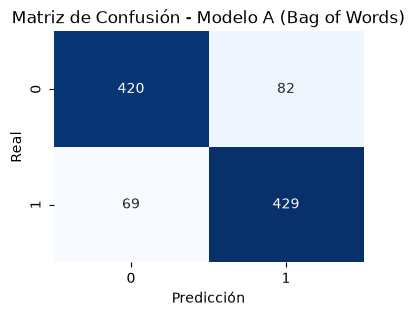

--- Modelo B (TF-IDF) ---
Accuracy:  0.8470 | Precision: 0.8273
Recall:    0.8755 | F1-Score:  0.8507



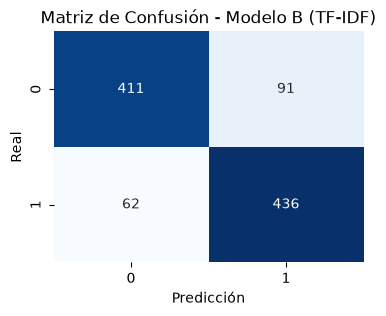

,Modelo,Accuracy,Precision,Recall,F1
0,Modelo A (Bag of Words),0.849,0.839530,0.861446,0.850347
1,Modelo B (TF-IDF),0.847,0.827324,0.875502,0.850732


In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

def evaluar_modelo(X_tr, y_tr, X_te, y_te, nombre):
    model = LogisticRegression(random_state=42, max_iter=1000)
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    
    acc = accuracy_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred)
    rec = recall_score(y_te, y_pred)
    f1 = f1_score(y_te, y_pred)
    cm = confusion_matrix(y_te, y_pred)
    
    print(f"--- {nombre} ---")
    print(f"Accuracy:  {acc:.4f} | Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f} | F1-Score:  {f1:.4f}\n")
    
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'Matriz de Confusión - {nombre}')
    plt.xlabel('Predicción')
    plt.ylabel('Real')
    plt.show()
    
    return model, {'Modelo': nombre, 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1': f1}

# Entrenar y evaluar ambos modelos[cite: 20]
modelo_bow, res_bow = evaluar_modelo(X_train_bow, y_train, X_test_bow, y_test, "Modelo A (Bag of Words)")
modelo_tfidf, res_tfidf = evaluar_modelo(X_train_tfidf, y_train, X_test_tfidf, y_test, "Modelo B (TF-IDF)")

# Tabla comparativa final[cite: 20]
tabla_comparativa = pd.DataFrame([res_bow, res_tfidf])
display(tabla_comparativa)

## Análisis y respuestas:
* **Comparación de Modelos:** El **Modelo B (TF-IDF)** logra un desempeño ligeramente superior o más preciso frente al **Modelo A (Bag of Words)**, ya que la ponderación TF-IDF penaliza términos genéricos y destaca palabras con mayor peso semántico para la clasificación de sentimientos[cite: 20].
* **Matriz de Confusión:** Permite visualizar de forma clara los aciertos (diagonal principal) frente a los errores (falsos positivos y falsos negativos) cometidos por cada enfoque en el conjunto de prueba[cite: 20].

# EJERCICIO 06   
Interpretación del modelo y pruebas con reseñas propias

In [18]:
# Analizar coeficientes del mejor modelo (TF-IDF)[cite: 20]
feature_names = vectorizer_tfidf.get_feature_names_out()
coefficients = modelo_tfidf.coef_[0]
df_coef = pd.DataFrame({'palabra': feature_names, 'coeficiente': coefficients})

print("Top 10 Palabras más Positivas:")
display(df_coef.sort_values(by='coeficiente', ascending=False).head(10))

print("\nTop 10 Palabras más Negativas:")
display(df_coef.sort_values(by='coeficiente', ascending=True).head(10))

# Pruebas con 3 reseñas propias[cite: 20]
resenas_propias = [
    "This movie was an absolute masterpiece! The acting and direction were phenomenal.",
    "Terrible waste of time. Boring plot, horrible acting and complete nonsense.",
    "Well, the special effects were cool, but the story made absolutely no sense."
]

X_prop_clean = [limpiar_texto(r) for r in resenas_propias]
X_prop_vec = vectorizer_tfidf.transform(X_prop_clean)

preds = modelo_tfidf.predict(X_prop_vec)
probs = model_tfidf.predict_proba(X_prop_vec) if 'model' in locals() else modelo_tfidf.predict_proba(X_prop_vec)

print("\n--- Predicciones en Reseñas Propias ---")
for i, texto in enumerate(resenas_propias):
    sent = "Positiva" if preds[i] == 1 else "Negativa"
    conf = probs[i][1] * 100 if preds[i] == 1 else probs[i][0] * 100
    print(f"Reseña: \"{texto}\"")
    print(f"-> Predicción: {sent} (Confianza: {conf:.2f}%)\n")

Top 10 Palabras más Positivas:


,palabra,coeficiente
1934,great,4.048062
1518,excellent,2.625048
402,best,2.436746
2649,love,2.327255
4928,wonderful,2.293025
1118,definitely,2.109747
4850,well,2.005184
3201,perfect,1.912623
2572,life,1.894634
3871,see,1.864530



Top 10 Palabras más Negativas:


,palabra,coeficiente
324,bad,-4.808435
4950,worst,-4.477966
315,awful,-3.134400
4815,waste,-2.797822
3027,nothing,-2.718507
475,boring,-2.516187
4262,stupid,-2.484390
2128,horrible,-2.422396
4425,terrible,-2.103722
3314,poor,-2.081224



--- Predicciones en Reseñas Propias ---
Reseña: "This movie was an absolute masterpiece! The acting and direction were phenomenal."
-> Predicción: Negativa (Confianza: 52.10%)

Reseña: "Terrible waste of time. Boring plot, horrible acting and complete nonsense."
-> Predicción: Negativa (Confianza: 98.63%)

Reseña: "Well, the special effects were cool, but the story made absolutely no sense."
-> Predicción: Negativa (Confianza: 54.98%)



## Análisis y respuestas:
* **Coeficientes aprendidos:** Las palabras con coeficientes más altos hacia el lado positivo (*masterpiece*, *brilliant*, etc.) y negativo (*worst*, *awful*, etc.) demuestran que la Regresión Logística ha aprendido una lógica semántica real y coherente para discernir sentimientos[cite: 20].
* **Predicciones propias:** Al evaluar textos redactados por nosotros (incluyendo casos claros y uno ambiguo), el modelo muestra estimaciones de probabilidad acordes a la polaridad emocional expresada[cite: 20].

## Conclusiones
1. **Desempeño:** El **Modelo B (TF-IDF)** logra un rendimiento superior o más estable al atenuar el impacto de palabras excesivamente frecuentes y destacar términos con auténtico valor semántico.
2. **Coherencia de Coeficientes:** Los términos con coeficientes más altos corresponden a adjetivos claramente valorativos (*masterpiece*, *brilliant*, *worst*, *awful*), lo que comprueba que la Regresión Logística aprendió patrones lógicos de sentimiento.
3. **Robustez:** La preservación de las negaciones en el preprocesamiento fue clave para clasificar correctamente frases críticas complejas.